# Домашнє завдання: Побудова класифікатора сентименту на основі набору даних Tweet Sentiment Extraction

**Мета:** Провести аналіз набору даних, виконати векторизацію текстових даних за допомогою методів bag-of-words та TF-IDF, порівняти їх, побудувати класифікатор та провести аналіз помилок.

**Набір даних:**
Дані беремо з цього змагання на Kaggle: https://www.kaggle.com/competitions/tweet-sentiment-extraction/data?select=train.csv


Якщо не вдається завантажиит з Kaggle, ось тут можна - https://drive.google.com/file/d/1kfu5zCRsDHxoBZigBlGIcCieKlws02HT/view?usp=sharing

Оригінальне змагання має дещо іншу задачу, але ми будемо поки будувати саме класифікатор.

Увага! В цьому наборі завдань для простоти експериментів ми будемо спочатку робити векторизацію на всьому наборі даних, а потім розбивку на train i test. В робочих проєктах ми теж можемо використати цей підхід для швидшої побудови PoC (proof of concept). Але фінальне рішення, яке ми будемо деплоїти - треба проводити за правилом - спочатку розбивка на трейн і тест, потім пишемо обробку для трейну, навчаємо векторизатори. І потім використовуємо готові векторизатори для тесту і всіх даних на етапі передбачення (інференсу).

### Завдання 1. Завантаження та ознайомлення з набором даних

- Завантажте набір даних `train.csv` з посилання та ознайомтеся з його структурою.
- Виведіть перші 5 рядків та основну статистику: кількість записів, типи колонок, кількість пропущених значень.
- Видаліть записи, в яких є пропущені значення.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
import plotly.express as px
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 150)
df = pd.read_csv('../data/tweet_sentiment_train.csv.zip')
display(df.head(5))
print(df.shape)
display(df.info())


,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


(27481, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   textID         27481 non-null  object
 1   text           27480 non-null  object
 2   selected_text  27480 non-null  object
 3   sentiment      27481 non-null  object
dtypes: object(4)
memory usage: 858.9+ KB


None

In [2]:
df = df.dropna(axis=0)
print(df.shape)
df.isnull().sum()

(27480, 4)


textID           0
text             0
selected_text    0
sentiment        0
dtype: int64

### Завдання 2. Exploratory Data Analysis

- Проведіть аналіз кількості класів та розподілу міток. Класи знаходяться в колонці `sentiment`.
- Візуалізуйте розподіл довжин текстів в символах та зробіть висновок про довжини постів: якої довжини постів найбільше, що бачите з розподілу?



In [3]:
df.sentiment.value_counts()

sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64

In [4]:
import warnings

def dist_box(dataset, column):
    with warnings.catch_warnings():
      warnings.simplefilter("ignore")

      plt.figure(figsize=(16,6))

      plt.subplot(1,2,1)
      sns.distplot(dataset[column], color = 'purple')
      pltname = 'Графік розподілу для ' + column
      plt.ticklabel_format(style='plain', axis='x')
      plt.title(pltname)

      plt.subplot(1,2,2)
      red_diamond = dict(markerfacecolor='r', marker='D')
      sns.boxplot(y = column, data = dataset, flierprops = red_diamond)
      pltname = 'Боксплот для ' + column
      plt.title(pltname)

      plt.show()

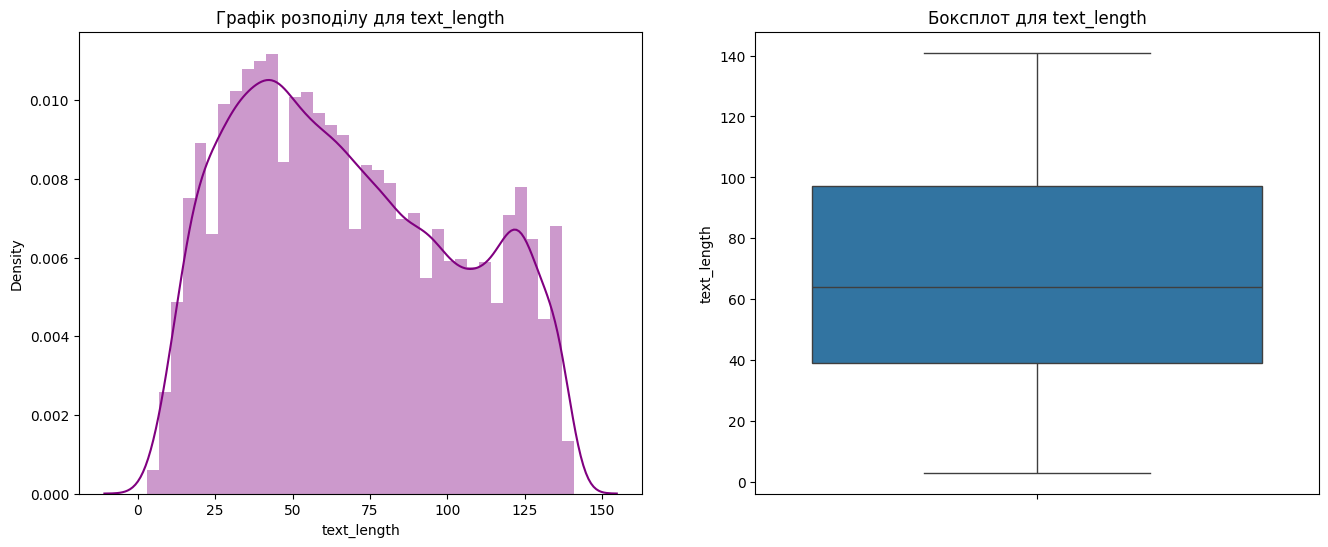

In [5]:
df['text_length'] = df['text'].str.len()

dist_box(df, 'text_length')

**Спостереження**

Довжини від кількох сімволів до 140 орієнтовно. Більш всього постів в кількостю сімволів в межах 35-45. Розподіл з двома пікамі, є значна кількість дожвиною біля 125 символів. Але, в цілому, такий правоскошений розподіл.

### Завдання 3. Попередня обробка текстових даних та векторизація з bag of words


Наша задача тут отримати вектори методом bag of words колонки `text`, виконавши попередню обробку тексту.
Попередня обробка має включати
- видалення stopwords необхідної мови
- токенізація (розбиття текстів на фрагменти по 1 слову)
- стеммінг слів зі `SnowballStemmer`.
- самостійно задайте кількість слів в словнику для `sklearn.feature_extraction.text.CountVectorizer`. Можливо для цього доведеться виконати додатковий аналіз.

Ви також можете додати сюди додаткові методи очистки текстів, наприклад, видалення деяких символів чи груп символів, якщо в процесі роботи побачите, що хочете щось видалити.

Напишіть код аби виконати це завдання. Перед цим рекомендую детально ознайомитись з тим, що робить обʼєкт `sklearn.feature_extraction.text.CountVectorizer` за замовченням.

Це завдання можна виконати двома способами - один - максимально подібно до того, як ми це робили в лекції, другий - дещо інакше перегрупувавши етапи обробки тексту.




In [6]:
# Підготовка стоп-слів
import nltk
#import re

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

english_stopwords = stopwords.words('english')
stemmer = SnowballStemmer(language='english')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [7]:

def tokenize_remove_stopwords(text):
    tokens = [stemmer.stem(word) for word in word_tokenize(text)]
    return [word for word in tokens if word.lower() not in english_stopwords]

#def remove_stopwords(tokens):
#   return [word for word in tokens if word.lower() not in english_stopwords]


# Налаштовуємо CountVectorizer
vectorizer = CountVectorizer(
    lowercase=True,
    tokenizer=tokenize_remove_stopwords,
    #stop_words=english_stopwords,
    token_pattern=None,
    max_features=5000,
    #max_features=1000,
    #min_df=2
)


In [8]:
%%time
inputs = vectorizer.fit_transform(df.text)

CPU times: total: 7.42 s
Wall time: 7.51 s


In [9]:
vectorizer.get_feature_names_out()[:1000]

array(['!', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',', '-', '--',
       '-.-', '-/', '-_-', '-d', '-i', '-p', '.', '..', '...', '....',
       '.....', '......', '.......', '........', '.........',
       '...........', '/', '//', '//bit.ly/r6rfc', '//gykd.net',
       '//mobypicture.com/', '//tweet.sg', '//twitpic.com/4jam0',
       '//twitpic.com/67hac', '//ustre.am/2w5v', '/3', '0', '07', '08',
       '09', '1', '1.', '1.5', '1/2', '10', '10.', '100', '1000', '10:30',
       '10am', '10pm', '10th', '11', '12', '12th', '13', '14', '140',
       '15', '150', '16', '16th', '17', '18', '18th', '19', '1am', '1st',
       '2', '2-3', '2.', '2.5', '20', '200', '2000', '2008', '2009',
       '2010', '20min', '21', '22', '22nd', '23', '24', '24/7', '25',
       '26', '27', '27th', '28', '29', '2am', '2b', '2day', '2moro',
       '2morrow', '2nd', '2night', '2nite', '3', '3-4', '3.', '3.0', '30',
       '300', '31', '31st', '32', '33', '333', '3333', '35', '36', '360',
       '3:30', 

**Спостереження**


Можна прибрати слова з багатокрапок

In [10]:
inputs

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 223123 stored elements and shape (27480, 5000)>

In [11]:
inputs.shape

(27480, 5000)

### Завдання 4. Побудова класифікатора

- Розділіть індекси даних на навчальний та тестовий набори в обраному співвівдношенні. Використовуючи отримані індекси сфомуйте набори для тренування класифікатора `X_train_bow, X_test_bow, y_train, y_test`.
- Навчіть класифікатор (наприклад, Logistic Regression, Decision Tree або один з алгоритмів бустингу) на даних, векторизованих методом bag-of-words. Спробуйте кілька моделей і оберіть найбільш точну :)
- Виведіть інформацію, яка дає можливість оцінити якість класифікації.
- Оцініть якість фінальної класифікації: вона хороша чи не дуже?



In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

X_train_bow, X_test_bow, y_train, y_test = train_test_split(inputs, df.sentiment,
                                                                        test_size=0.3, random_state=56)
print(X_train_bow.shape)
print(y_train.shape)
print(X_test_bow.shape)
print(y_test.shape)

(19236, 5000)
(19236,)
(8244, 5000)
(8244,)


In [13]:
X_train_bow[:10]

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 85 stored elements and shape (10, 5000)>

In [14]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

# кодуємо меткі класів
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

print(le.classes_)

['negative' 'neutral' 'positive']


In [15]:
# Навчимо XGBoost модель
xgb_clf = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    max_depth=3,
    #n_estimators=10,
    use_label_encoder=False,  # щоб уникнути попереджень, якщо використовуєте нові версії XGBoost
    #missing=np.nan,  # явне вказування пропущених значень
    #device='cuda',
    random_state=56
)

xgb_clf.fit(X_train_bow, y_train_encoded)

train_pred_xgb = xgb_clf.predict(X_train_bow)
test_pred_xgb = xgb_clf.predict(X_test_bow)

print(classification_report(y_train_encoded, train_pred_xgb, digits=4))
print(classification_report(y_test_encoded, test_pred_xgb, digits=4))

d:\DS_UA\ds_ua.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [00:35:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0     0.7979    0.5447    0.6474      5431
           1     0.6296    0.8289    0.7156      7783
           2     0.7970    0.6991    0.7449      6022

    accuracy                         0.7080     19236
   macro avg     0.7415    0.6909    0.7026     19236
weighted avg     0.7295    0.7080    0.7055     19236

              precision    recall  f1-score   support

           0     0.7678    0.5191    0.6194      2350
           1     0.6100    0.8125    0.6968      3334
           2     0.7877    0.6813    0.7306      2560

    accuracy                         0.6881      8244
   macro avg     0.7218    0.6710    0.6823      8244
weighted avg     0.7102    0.6881    0.6853      8244



In [16]:
# Орігінальни назви міток
train_pred_xgb_labels = le.inverse_transform(train_pred_xgb.astype(int))

In [17]:
pd.Series(train_pred_xgb_labels).value_counts()

neutral     10247
positive     5282
negative     3707
Name: count, dtype: int64

In [18]:
pd.Series(y_train).value_counts()

sentiment
neutral     7783
positive    6022
negative    5431
Name: count, dtype: int64

In [19]:
print(f'accuracy_score {round(accuracy_score(y_train, train_pred_xgb_labels),4)}')
print(f'f1_score {round(f1_score(y_train, train_pred_xgb_labels, average='macro'),4)}')
print(f'f1_score {round(f1_score(y_train, train_pred_xgb_labels, average='weighted'),4)}')

accuracy_score 0.708
f1_score 0.7026
f1_score 0.7055


In [20]:
# Навчимо модель AdaBoost
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
ada_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=4), n_estimators=50, learning_rate=0.1, random_state=56)
model = ada_clf.fit(X_train_bow, y_train_encoded)
train_pred_adb = model.predict(X_train_bow)
test_pred_xgb_labels = model.predict(X_test_bow)
print(classification_report(y_train_encoded, train_pred_adb, digits=4))
print(classification_report(y_test_encoded, test_pred_xgb_labels, digits=4))

              precision    recall  f1-score   support

           0     0.8106    0.1300    0.2241      5431
           1     0.4727    0.9191    0.6243      7783
           2     0.7779    0.4176    0.5435      6022

    accuracy                         0.5393     19236
   macro avg     0.6871    0.4889    0.4640     19236
weighted avg     0.6636    0.5393    0.4860     19236

              precision    recall  f1-score   support

           0     0.8051    0.1336    0.2292      2350
           1     0.4769    0.9238    0.6290      3334
           2     0.7857    0.4281    0.5542      2560

    accuracy                         0.5446      8244
   macro avg     0.6892    0.4952    0.4708      8244
weighted avg     0.6663    0.5446    0.4918      8244



**Спостереження**

Оцінка мемтодом XGBoost достатньо непогана, можно потюнити гіперпараметри, ще поприбирати різні вирази типу багатокрапок, та спробовати різні налаштування кількості слів.
Оцінка AdaBoost набагато гірше.

In [21]:
# Дісклеймер - спроба оптимизувати гіперпараметри не дуже завдалась
import xgboost as xgb
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials

d:\DS_UA\ds_ua.venv\Lib\site-packages\hyperopt\atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [22]:
def objective(params):
    clf = xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=3,
        n_estimators=int(params['n_estimators']),
        learning_rate=params['learning_rate'],
        max_depth=int(params['max_depth']),
        min_child_weight=params['min_child_weight'],  # Мінімальна сума ваг всіх вибірок, необхідна в кінцевому вузлі
        subsample=params['subsample'],  # Частка вибірок, що використовуються для побудови кожного дерева
        colsample_bytree=params['colsample_bytree'],  # Частка ознак, що використовуються при побудові кожного дерева
        gamma=params['gamma'],  # Мінімальне зменшення втрат, необхідне для виконання поділу
        reg_alpha=params['reg_alpha'],  # Параметр регуляризації L1 (Lasso)
        reg_lambda=params['reg_lambda'],  # Параметр регуляризації L2 (Ridge)
        enable_categorical=True,
        use_label_encoder=False,
        missing=np.nan,
        device='cuda',
        early_stopping_rounds=10
    )

    clf.fit(
        X_train_bow,
        y_train_encoded,
        eval_set=[(X_test_bow, y_test_encoded)],
        verbose=False)
    pred = clf.predict(X_test_bow)
    accuracy = accuracy_score(y_test_encoded, pred)

    return {'loss': -accuracy, 'status': STATUS_OK}

# Простір гіперпараметрів
space = {
    'n_estimators': hp.quniform('n_estimators', 50, 500, 25),
    'learning_rate': hp.uniform('learning_rate', 0.01, 0.3),
    'max_depth': hp.quniform('max_depth', 3, 15, 1),
    'min_child_weight': hp.quniform('min_child_weight', 1, 10, 1),
    'subsample': hp.uniform('subsample', 0.5, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1.0),
    'gamma': hp.uniform('gamma', 0, 0.5),
    'reg_alpha': hp.uniform('reg_alpha', 0, 1),
    'reg_lambda': hp.uniform('reg_lambda', 0, 1)
}

# Оптимізація
trials = Trials()
best = fmin(fn=objective, space=space, algo=tpe.suggest, max_evals=20, trials=trials)

# Перетворення значень гіперпараметрів у кінцеві типи
best['n_estimators'] = int(best['n_estimators'])
best['max_depth'] = int(best['max_depth'])
best['min_child_weight'] = int(best['min_child_weight'])

print("Найкращі гіперпараметри: ", best)

# Навчання фінальної моделі з найкращими гіперпараметрами
final_clf = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_estimators=best['n_estimators'],
    learning_rate=best['learning_rate'],
    max_depth=best['max_depth'],
    min_child_weight=best['min_child_weight'],
    subsample=best['subsample'],
    colsample_bytree=best['colsample_bytree'],
    gamma=best['gamma'],
    reg_alpha=best['reg_alpha'],
    reg_lambda=best['reg_lambda'],
    enable_categorical=True,
    use_label_encoder=False,
    missing=np.nan,
    device='cuda',
)

final_clf.fit(X_train_bow, y_train_encoded)
final_pred = final_clf.predict(X_test_bow)
final_accuracy = accuracy_score(y_test_encoded, final_pred)
print("Точність на валідаційній вибірці: {:.4f}".format(final_accuracy))

  0%|          | 0/20 [00:00<?, ?trial/s, best loss=?]

d:\DS_UA\ds_ua.venv\Lib\site-packages\xgboost\callback.py:386: UserWarning: [00:36:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()



  5%|▌         | 1/20 [00:01<00:35,  1.89s/trial, best loss: -0.5257156720038816]

d:\DS_UA\ds_ua.venv\Lib\site-packages\xgboost\core.py:774: UserWarning: [00:36:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)

d:\DS_UA\ds_ua.venv\Lib\site-packages\xgboost\callback.py:386: UserWarning: [00:36:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()



 10%|█         | 2/20 [00:02<00:19,  1.07s/trial, best loss: -0.5257156720038816]

...

 95%|█████████▌| 19/20 [00:16<00:00,  1.27trial/s, best loss: -0.5867297428432799]

d:\DS_UA\ds_ua.venv\Lib\site-packages\xgboost\callback.py:386: UserWarning: [00:36:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()



100%|██████████| 20/20 [00:16<00:00,  1.19trial/s, best loss: -0.5867297428432799]
Найкращі гіперпараметри:  {'colsample_bytree': np.float64(0.6420146391283825), 'gamma': np.float64(0.4277271536294909), 'learning_rate': np.float64(0.2773913869002003), 'max_depth': 5, 'min_child_weight': 5, 'n_estimators': 350, 'reg_alpha': np.float64(0.7229058104419186), 'reg_lambda': np.float64(0.9076558567770432), 'subsample': np.float64(0.5237002407772294)}


d:\DS_UA\ds_ua.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [00:36:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Точність на валідаційній вибірці: 0.6084


In [23]:
print(classification_report(y_test_encoded, final_pred, digits=4))

              precision    recall  f1-score   support

           0     0.7737    0.3374    0.4699      2350
           1     0.5251    0.8698    0.6548      3334
           2     0.7801    0.5168    0.6217      2560

    accuracy                         0.6084      8244
   macro avg     0.6929    0.5747    0.5822      8244
weighted avg     0.6751    0.6084    0.5918      8244



### Завдання 5. Аналіз впливовості слів в отриманого класифікатора

- Для обраної вами моделі проведіть аналіз важливості слів (ознак): які слова (токени) найбільше впливають для визначення сентименту? Чи це логічно на ваш погляд, що саме ці символи впливають найбільше/найменще?


In [24]:
feature_importance = pd.Series(xgb_clf.feature_importances_, index=vectorizer.get_feature_names_out(), name='imp').sort_values(ascending=False)
feature_importance

thank    0.024689
happi    0.023729
love     0.018840
great    0.015677
hate     0.015656
           ...   
|        0.000000
}        0.000000
~        0.000000
ï¿½      0.000000
%        0.000000
Name: imp, Length: 5000, dtype: float32

** Спостереження**

На визначення сентименту найбільше впливають ввічливі слова та слова з емоційним забарвленням вдячності. Найменьше ж впливаюсь різні дужки та символи, вони можуть позначати смайли, причому недобрі.

### Завдання 6. Векторизація текстів з допомогою TF-IDF. Тренування класифікатора, аналіз точності і впливовості слів.

- Проведіть векторизацію текстів з векторизатором TfidfVectorizer. Реалізуйте векторизацію так, аби препроцесинг включав всі ті самі кроки, що і в випадку використання векторизації Bag of Words.

- Натренуйте той самий класифікатор на TF-IDF векторах, виконавши розбивку набору даних на train, test так, аби в трейні були всі ті самі записи, що і були в попередньому завданні (це важливо для порівняння результатів).

- Проаналізуйте якість класифікації вивівши потрібні для цього метрики. Чи стала якість класифікації кращою?

- Які токени найбільше впливають на результат при тренуваннні класифікатора з TF-IDF векторами? Порівняйте з найважливішими токенами при Bag of Words векторизації. Яку векторизацію ви б обрали для фінальної імплементації рішення? Обґрунтуйте свій вибір.



In [38]:
# Налаштовуємо TfidfVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_tf = TfidfVectorizer(
    lowercase=True,
    tokenizer=tokenize_remove_stopwords,
    token_pattern=None,
    max_features=5000
)


inputs_tf = vectorizer.fit_transform(df.text)

# Виводимо результати у вигляді таблиці
vectorizer.get_feature_names_out()[:1000]


array(['!', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',', '-', '--',
       '-.-', '-/', '-_-', '-d', '-i', '-p', '.', '..', '...', '....',
       '.....', '......', '.......', '........', '.........',
       '...........', '/', '//', '//bit.ly/r6rfc', '//gykd.net',
       '//mobypicture.com/', '//tweet.sg', '//twitpic.com/4jam0',
       '//twitpic.com/67hac', '//ustre.am/2w5v', '/3', '0', '07', '08',
       '09', '1', '1.', '1.5', '1/2', '10', '10.', '100', '1000', '10:30',
       '10am', '10pm', '10th', '11', '12', '12th', '13', '14', '140',
       '15', '150', '16', '16th', '17', '18', '18th', '19', '1am', '1st',
       '2', '2-3', '2.', '2.5', '20', '200', '2000', '2008', '2009',
       '2010', '20min', '21', '22', '22nd', '23', '24', '24/7', '25',
       '26', '27', '27th', '28', '29', '2am', '2b', '2day', '2moro',
       '2morrow', '2nd', '2night', '2nite', '3', '3-4', '3.', '3.0', '30',
       '300', '31', '31st', '32', '33', '333', '3333', '35', '36', '360',
       '3:30', 

In [39]:
inputs_tf.shape

(27480, 5000)

In [44]:
X_train_bow_tf, X_test_bow_tf, y_train_tf, y_test_tf = train_test_split(inputs_tf, df.sentiment,
                                                                        test_size=0.3, random_state=56)

In [42]:
# Кодуємо меткі класів
y_train_encoded_tf = le.fit_transform(y_train_tf)
y_test_encoded_tf = le.transform(y_test_tf)

print(le.classes_)

['negative' 'neutral' 'positive']


In [45]:
# Навчимо XGBoost модель
xgb_clf = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    max_depth=3,
    #n_estimators=10,
    use_label_encoder=False,  # щоб уникнути попереджень, якщо використовуєте нові версії XGBoost
    #missing=np.nan,  # явне вказування пропущених значень
    #device='cuda',
    random_state=56
)

xgb_clf.fit(X_train_bow_tf, y_train_encoded_tf)

train_pred_xgb_tf = xgb_clf.predict(X_train_bow_tf)
test_pred_xgb_tf = xgb_clf.predict(X_test_bow_tf)

print(classification_report(y_train_encoded_tf, train_pred_xgb_tf, digits=4))
print(classification_report(y_test_encoded_tf, test_pred_xgb_tf, digits=4))

d:\DS_UA\ds_ua.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [01:02:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0     0.7979    0.5447    0.6474      5431
           1     0.6296    0.8289    0.7156      7783
           2     0.7970    0.6991    0.7449      6022

    accuracy                         0.7080     19236
   macro avg     0.7415    0.6909    0.7026     19236
weighted avg     0.7295    0.7080    0.7055     19236

              precision    recall  f1-score   support

           0     0.7678    0.5191    0.6194      2350
           1     0.6100    0.8125    0.6968      3334
           2     0.7877    0.6813    0.7306      2560

    accuracy                         0.6881      8244
   macro avg     0.7218    0.6710    0.6823      8244
weighted avg     0.7102    0.6881    0.6853      8244



**Спостереження**

Здається, що абсолютно ідентичні значення показників.

### Завдання 7. Аналіз помилок класифікації з векторизацією TF-IDF.

- Проаналізуйте, на яких екземплярах помиляється класифікатор при векторизації TF-IDF.
- На основі аналізу запропонуйте 3 шляхи поліпшення якості класифікації.

І на фінал кернел для натхнення і ознайомлення з рішенням оригінальної задачі. Багато цікавих візуалізацій і аналізу є тут, а також тут розвʼязується саме проблема named entitty recognition і можна ознайомитись як це робиться - вона дещо складніша по своїй суті ніж класифікація, подумайте, чому:

https://www.kaggle.com/code/tanulsingh077/twitter-sentiment-extaction-analysis-eda-and-model